# Deformable DETR на своих картинках

Основная модель - `SenseTime/deformable-detr` (ResNet-50, 50 эпох; в статье 43.8 AP на COCO val, у выложенных весов по README 44.5).
Для сравнения те же картинки прогоняются через `SenseTime/deformable-detr-single-scale` (одна карта признаков вместо четырёх) и через обычный DETR `facebook/detr-resnet-50`.

In [1]:
import glob
import os
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForObjectDetection
from transformers.utils import logging

logging.set_verbosity_error()
logging.disable_progress_bar()
%config InlineBackend.figure_format = "jpeg"
os.makedirs("results", exist_ok=True)
files = sorted(glob.glob("images/*.jpg"))
imgs = {os.path.basename(f)[:-4]: Image.open(f).convert("RGB") for f in files}
print(len(imgs), "картинок")

W1108 22:26:22.903000 44698 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


15 картинок


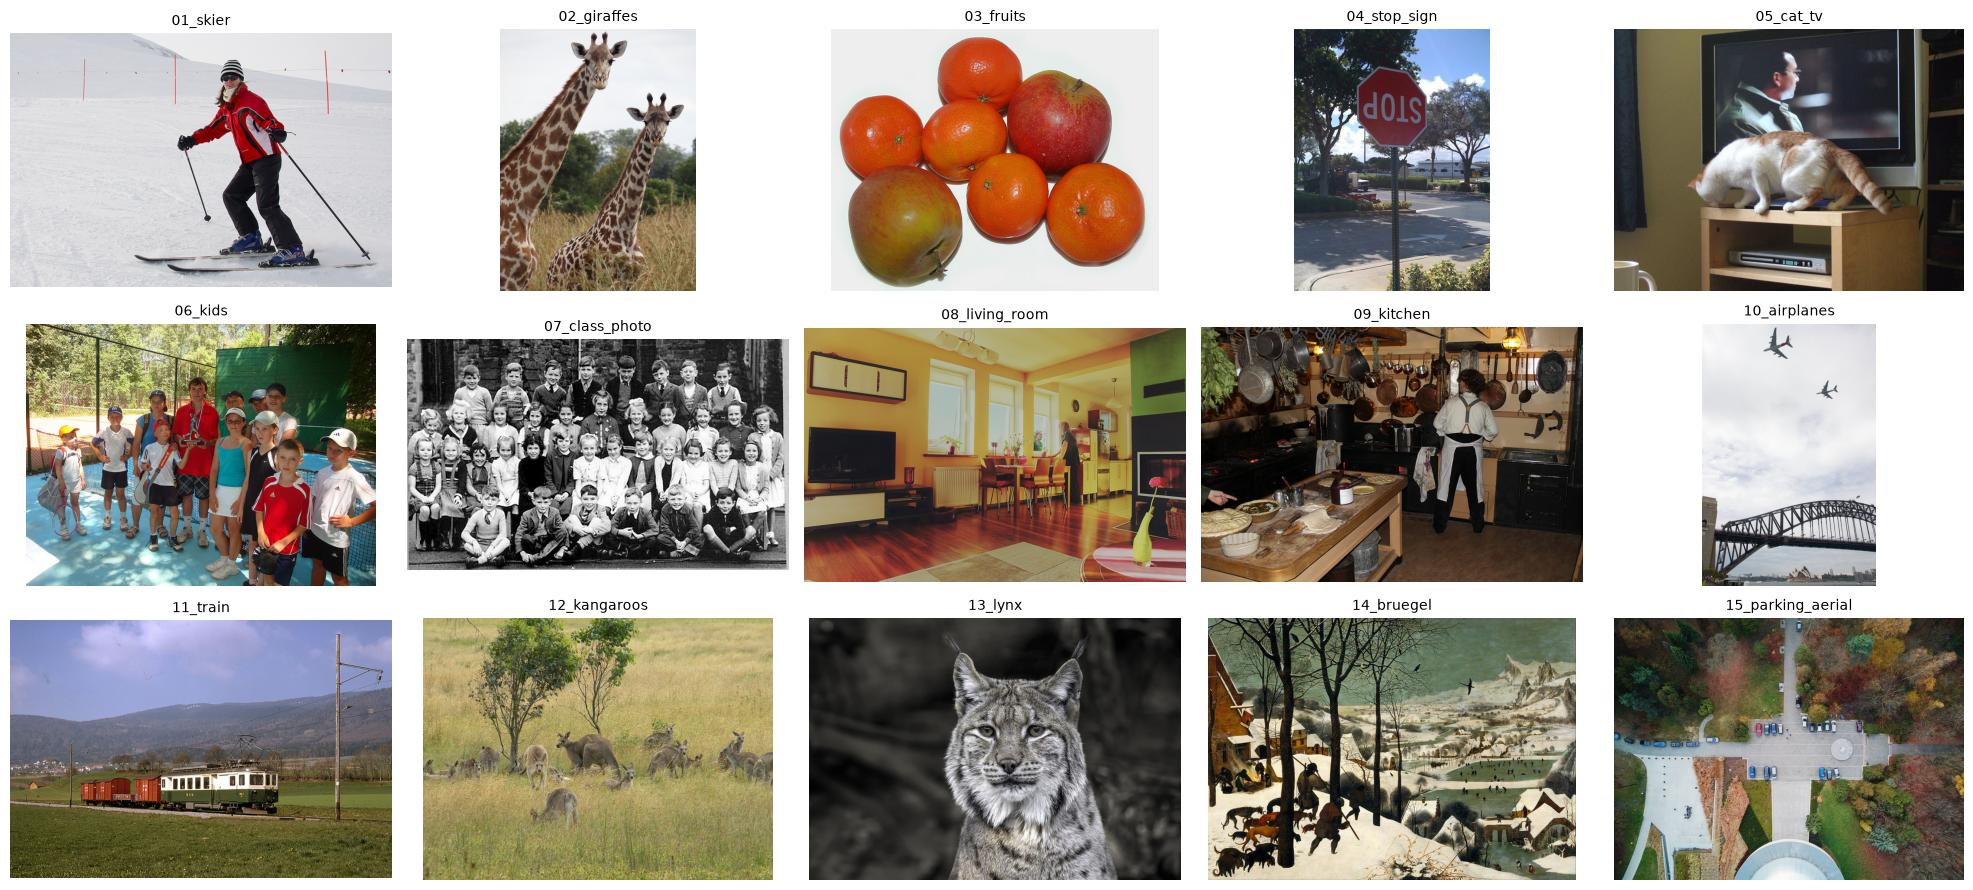

In [2]:
fig, axes = plt.subplots(3, 5, figsize=(20, 9))
for ax, (n, img) in zip(axes.flat, imgs.items()):
    ax.imshow(img)
    ax.set_title(n, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/inputs.png", dpi=80)

## Модели

У Deformable DETR классификация через сигмоиду и focal loss, скоры получаются заметно ниже, чем у DETR с softmax. Поэтому порог разный: 0.3 для Deformable DETR и 0.7 для DETR (подбирал по графику ниже так, чтобы число боксов было примерно одинаковым).

In [3]:
def load(name):
    return AutoImageProcessor.from_pretrained(name), AutoModelForObjectDetection.from_pretrained(name).eval()


models = {
    "deformable": load("SenseTime/deformable-detr"),
    "single_scale": load("SenseTime/deformable-detr-single-scale"),
    "detr": load("facebook/detr-resnet-50"),
}
THR = {"deformable": 0.3, "single_scale": 0.3, "detr": 0.7}

In [4]:
@torch.no_grad()
def predict(key, img):
    proc, model = models[key]
    out = model(**proc(images=img, return_tensors="pt"))
    r = proc.post_process_object_detection(out, threshold=0.05, target_sizes=[img.size[::-1]])[0]
    labels = [model.config.id2label[int(l)] for l in r["labels"]]
    return list(zip(labels, r["scores"].tolist(), r["boxes"].tolist()))


raw, sec = {}, {}
for k in models:
    t = time.time()
    raw[k] = {n: predict(k, img) for n, img in imgs.items()}
    sec[k] = round((time.time() - t) / len(imgs), 2)
dets = {k: {n: [d for d in raw[k][n] if d[1] >= THR[k]] for n in imgs} for k in models}
pd.Series(sec).to_csv("results/time.csv")
sec

{'deformable': 4.0, 'single_scale': 0.98, 'detr': 1.05}

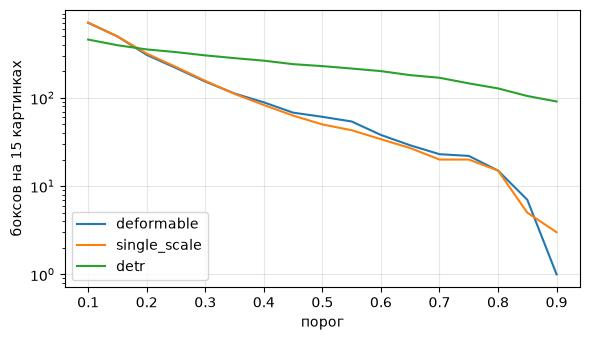

In [5]:
thrs = np.arange(0.1, 0.95, 0.05)
plt.figure(figsize=(6, 3.5))
for k in models:
    plt.plot(thrs, [sum(sum(s >= t for _, s, _ in raw[k][n]) for n in imgs) for t in thrs], label=k)
plt.xlabel("порог")
plt.ylabel("боксов на 15 картинках")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("results/threshold.png", dpi=120)

## Результаты Deformable DETR

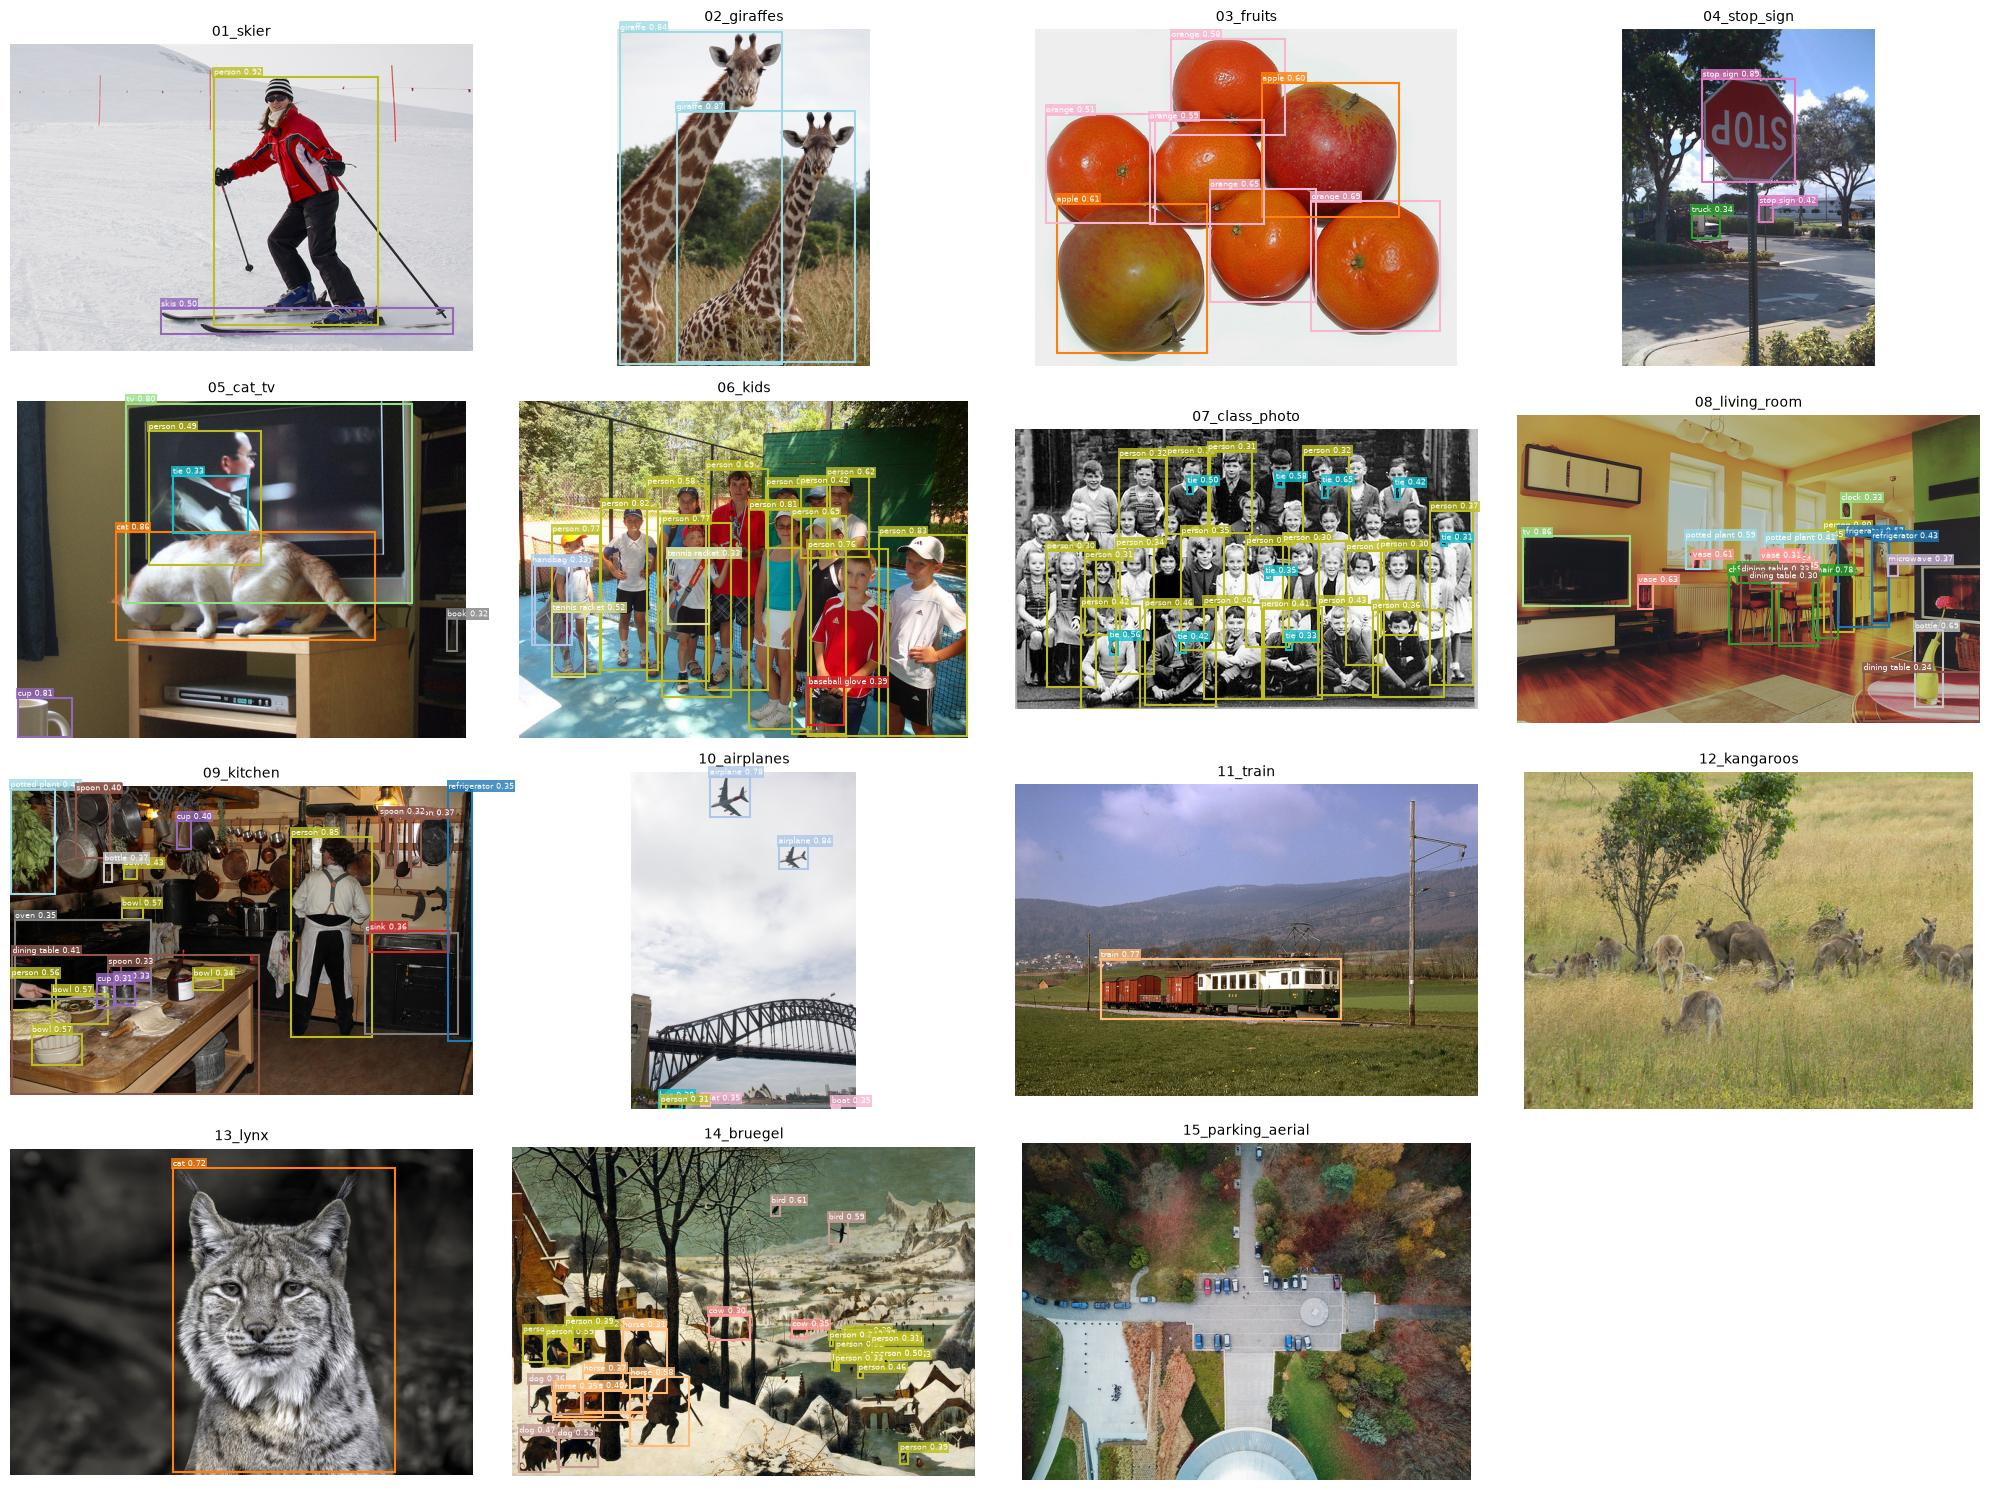

In [6]:
labels = sorted(set(models["detr"][1].config.id2label.values()))
COLORS = {l: plt.cm.tab20(i % 20) for i, l in enumerate(labels)}


def draw(ax, img, d, title=None, fs=7):
    ax.imshow(img)
    for label, score, (x0, y0, x1, y1) in d:
        c = COLORS[label]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color=c, lw=1.5))
        ax.text(x0, y0, f"{label} {score:.2f}", fontsize=fs, color="white", va="bottom",
                bbox=dict(facecolor=c, alpha=0.8, pad=1, lw=0))
    if title:
        ax.set_title(title, fontsize=10)
    ax.axis("off")


fig, axes = plt.subplots(4, 4, figsize=(20, 15))
for ax, (n, img) in zip(axes.flat, imgs.items()):
    draw(ax, img, dets["deformable"][n], n, fs=6)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("results/deformable_all.png", dpi=90)

In [7]:
def is_small(box):
    x0, y0, x1, y1 = box
    return (x1 - x0) * (y1 - y0) < 32 ** 2


rows = []
for n in imgs:
    row = {"image": n}
    for k in models:
        row[k] = len(dets[k][n])
        row[k + "_small"] = sum(is_small(b) for _, _, b in dets[k][n])
    row["classes"] = ", ".join(f"{l} {c}" for l, c in Counter(l for l, _, _ in dets["deformable"][n]).most_common())
    rows.append(row)
summary = pd.DataFrame(rows).set_index("image")
summary.to_csv("results/summary.csv")
summary

,deformable,deformable_small,single_scale,single_scale_small,detr,detr_small,classes
image,,,,,,,
01_skier,2,0,2,0,2,0,"person 1, skis 1"
02_giraffes,2,0,2,0,2,0,giraffe 2
03_fruits,7,0,7,0,7,0,"orange 5, apple 2"
04_stop_sign,3,1,2,0,3,0,"stop sign 2, truck 1"
05_cat_tv,6,1,6,1,5,1,"cat 1, cup 1, tv 1, person 1, tie 1, book 1"
06_kids,18,0,18,0,22,2,"person 12, handbag 3, tennis racket 2, basebal..."
07_class_photo,28,9,24,10,38,13,"person 19, tie 9"
08_living_room,23,11,24,10,24,10,"vase 6, chair 4, dining table 3, person 2, pot..."
09_kitchen,24,10,17,6,15,5,"spoon 7, bowl 5, cup 3, person 2, oven 2, dini..."


In [8]:
summary.drop(columns="classes").sum()

deformable            153
deformable_small       56
single_scale          156
single_scale_small     56
detr                  169
detr_small             67
dtype: int64

## Сравнение с single-scale и DETR

Картинки, где много мелких объектов.

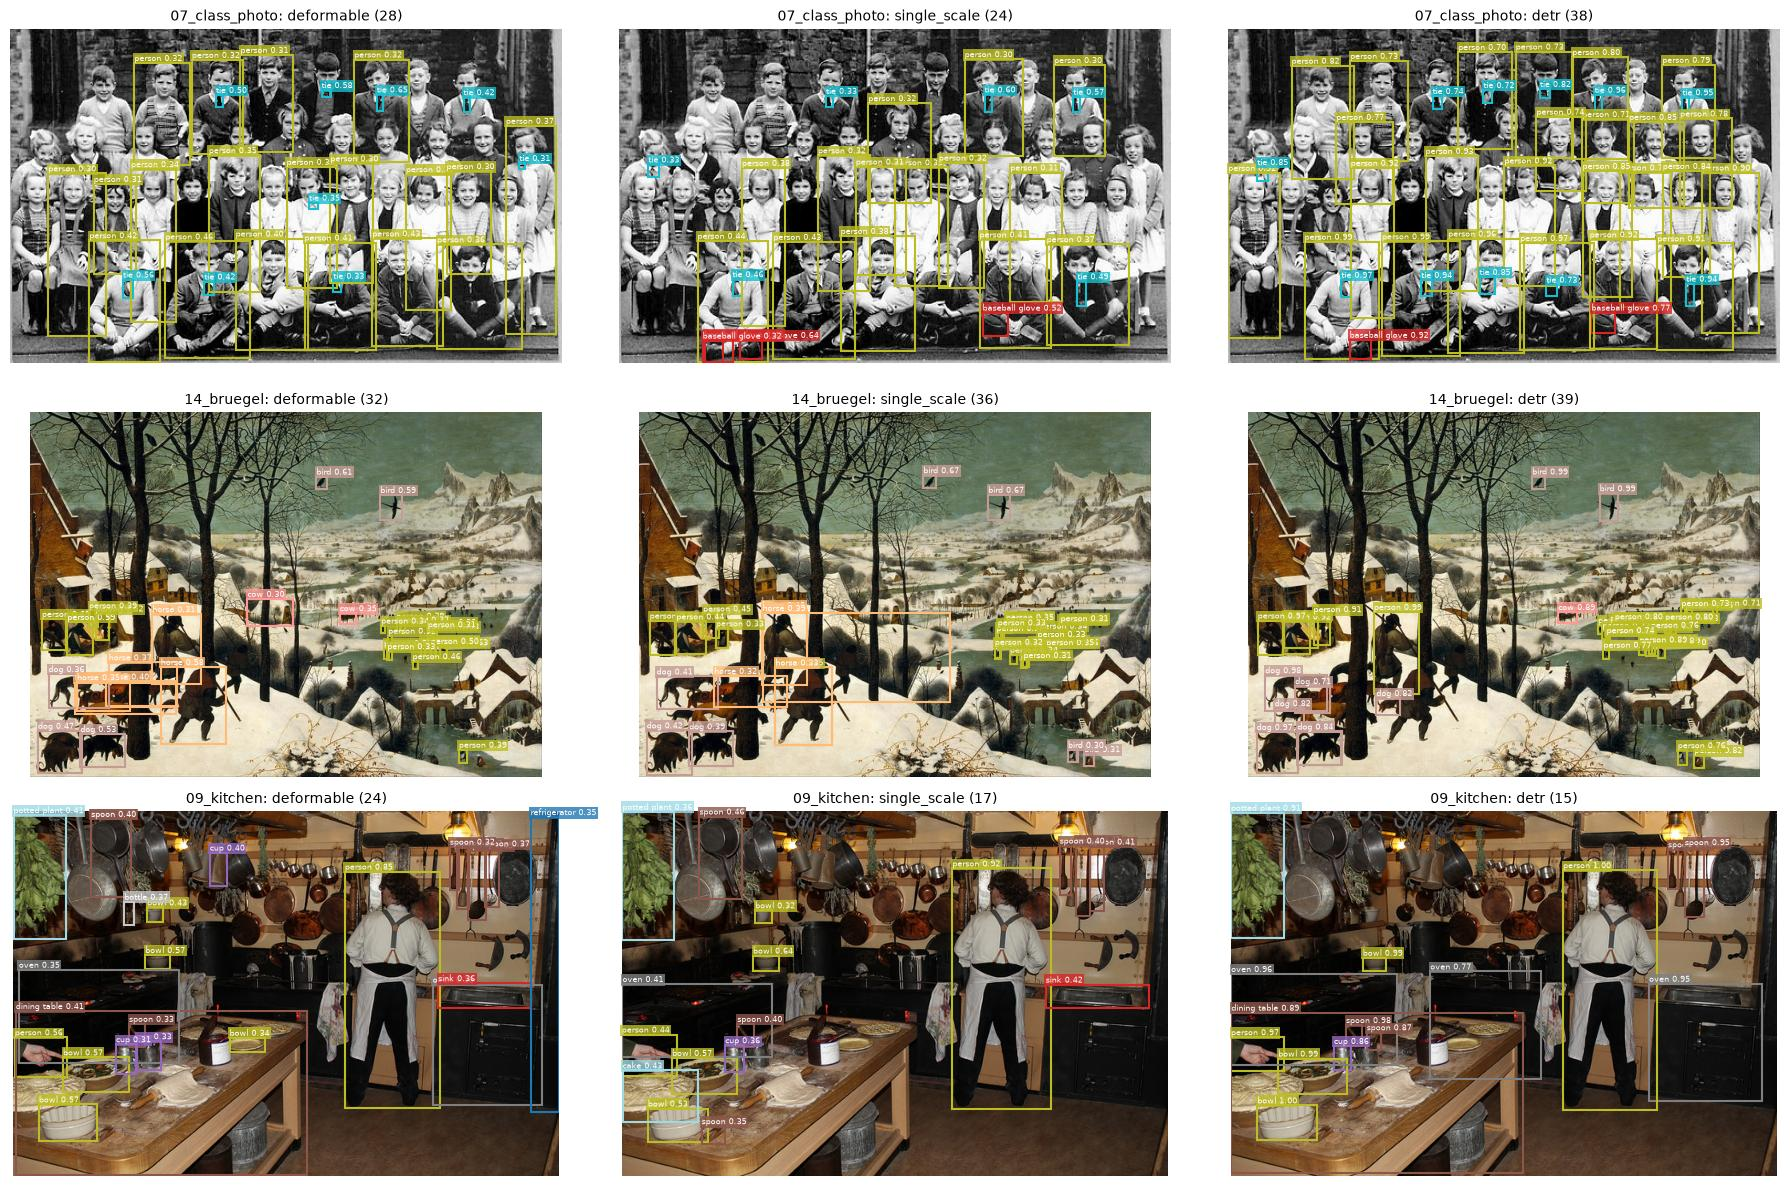

In [9]:
show = ["07_class_photo", "14_bruegel", "09_kitchen"]
fig, axes = plt.subplots(len(show), 3, figsize=(18, 4 * len(show)))
for i, n in enumerate(show):
    for j, k in enumerate(models):
        draw(axes[i, j], imgs[n], dets[k][n], f"{n}: {k} ({len(dets[k][n])})", fs=6)
plt.tight_layout()
plt.savefig("results/compare.png", dpi=90)

## Ошибки

Что модели выдают на картинках, где при пороге почти ничего нет (топ-3 по скору).

In [10]:
def top(k, n, m=3):
    return [(l, round(s, 2)) for l, s, _ in sorted(raw[k][n], key=lambda d: -d[1])[:m]]


pd.DataFrame({k: {n: top(k, n) for n in ["12_kangaroos", "13_lynx", "15_parking_aerial"]} for k in models})

,deformable,single_scale,detr
12_kangaroos,"[(sheep, 0.26), (bird, 0.23), (zebra, 0.22)]","[(sheep, 0.53), (sheep, 0.5), (sheep, 0.49)]","[(sheep, 0.85), (sheep, 0.56), (sheep, 0.35)]"
13_lynx,"[(cat, 0.72), (cat, 0.09), (bird, 0.08)]","[(cat, 0.77), (bench, 0.1), (couch, 0.09)]","[(cat, 1.0)]"
15_parking_aerial,"[(car, 0.28), (traffic light, 0.27), (traffic ...","[(clock, 0.35), (toilet, 0.27), (cell phone, 0...","[(clock, 0.95), (toilet, 0.67), (car, 0.6)]"


Классная фотография при разных порогах.

In [11]:
pd.DataFrame({f"{k} {t}": Counter(l for l, s, _ in raw[k]["07_class_photo"] if s >= t)
              for k, t in [("deformable", 0.5), ("deformable", 0.3), ("detr", 0.7)]}).fillna(0).astype(int)

,deformable 0.5,deformable 0.3,detr 0.7
tie,3,9,11
person,0,19,25
baseball glove,0,0,2


Дубликаты: боксы одного класса с IoU > 0.7 (NMS нет, так что всё, что прошло порог, остаётся).

In [12]:
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    area = lambda r: (r[2] - r[0]) * (r[3] - r[1])
    return w * h / (area(a) + area(b) - w * h)


dups = []
for k in models:
    for n in imgs:
        d = dets[k][n]
        for i in range(len(d)):
            for j in range(i + 1, len(d)):
                if d[i][0] == d[j][0] and iou(d[i][2], d[j][2]) > 0.7:
                    dups.append((k, n, d[i][0], round(d[i][1], 2), round(d[j][1], 2), round(iou(d[i][2], d[j][2]), 2), d[i][2], d[j][2]))
dups = pd.DataFrame(dups, columns=["model", "image", "class", "score1", "score2", "iou", "box1", "box2"])
dups.drop(columns=["box1", "box2"])

,model,image,class,score1,score2,iou
0,deformable,06_kids,handbag,0.40,0.33,0.77
1,deformable,08_living_room,vase,0.32,0.31,0.79
2,deformable,09_kitchen,spoon,0.45,0.40,0.97
3,deformable,14_bruegel,person,0.57,0.50,0.73
4,single_scale,06_kids,person,0.37,0.35,0.89
5,single_scale,08_living_room,dining table,0.31,0.30,0.92
6,single_scale,08_living_room,vase,0.31,0.31,0.92
7,single_scale,14_bruegel,bird,0.33,0.30,0.85
8,detr,14_bruegel,dog,0.77,0.84,0.95
9,detr,14_bruegel,person,0.73,0.89,0.91


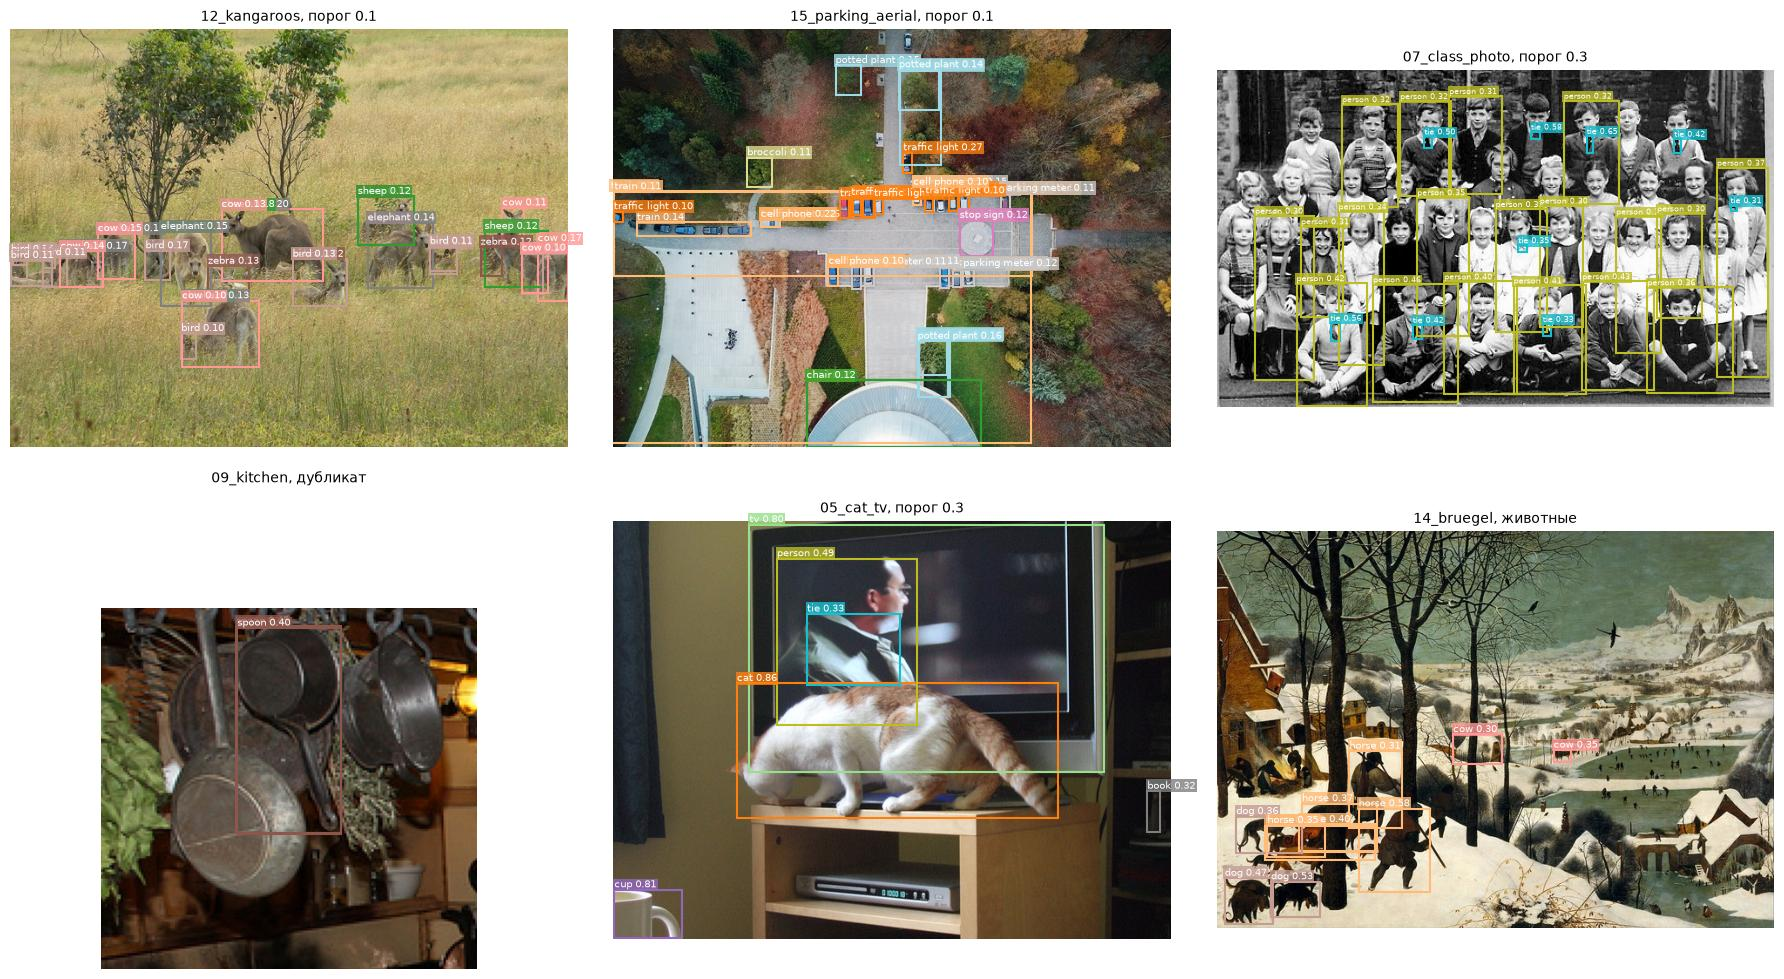

In [13]:
def zoom(ax, boxes, pad=30):
    ax.set_xlim(min(b[0] for b in boxes) - pad, max(b[2] for b in boxes) + pad)
    ax.set_ylim(max(b[3] for b in boxes) + pad, min(b[1] for b in boxes) - pad)


def low(n, t=0.1):
    return [d for d in raw["deformable"][n] if d[1] >= t]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
draw(axes[0, 0], imgs["12_kangaroos"], low("12_kangaroos"), "12_kangaroos, порог 0.1")
draw(axes[0, 1], imgs["15_parking_aerial"], low("15_parking_aerial"), "15_parking_aerial, порог 0.1")
draw(axes[0, 2], imgs["07_class_photo"], dets["deformable"]["07_class_photo"], "07_class_photo, порог 0.3", fs=6)

d = dups[(dups.model == "deformable") & (dups.image == "09_kitchen")].iloc[0]
draw(axes[1, 0], imgs["09_kitchen"], [x for x in dets["deformable"]["09_kitchen"] if x[2] in (d.box1, d.box2)], "09_kitchen, дубликат")
zoom(axes[1, 0], [d.box1, d.box2], pad=60)

draw(axes[1, 1], imgs["05_cat_tv"], dets["deformable"]["05_cat_tv"], "05_cat_tv, порог 0.3")

draw(axes[1, 2], imgs["14_bruegel"], [x for x in dets["deformable"]["14_bruegel"] if x[0] in ("horse", "dog", "cow")], "14_bruegel, животные")
plt.tight_layout()
plt.savefig("results/errors.png", dpi=90)

Что видно:

- кенгуру в COCO нет, при пороге 0.3 модель не находит ничего, ниже порога это sheep / bird / zebra / cow с 0.1-0.26
- машины сверху не находятся: лучший скор car 0.28, и тот на куполе внизу, на самих машинах traffic light, cell phone, parking meter
- на классной фотографии часть детей пропущена, некоторые боксы захватывают двоих, скоры 0.3-0.45, а галстуки находятся увереннее людей
- без NMS остаются дубликаты (spoon 0.45 и 0.40 с IoU 0.97)
- на картине собаки становятся horse, люди на льду мелкие и находятся через раз
- человек на экране телевизора детектится как person (в COCO так тоже бывает размечено, спорный случай)

Подробнее в отчёте.